# Lab: CV w/CNNs

# Part 1: Libraries & Preprocessing

### Step 1: Libraries

Bring in the germane libraries.

In [2]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

# TensorFlow / Keras functions
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential, Input, Model
from tensorflow.keras.layers import Dense, Conv2D, Flatten, MaxPooling2D
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping

I0000 00:00:1792086721.103022    1356 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792086724.234637    1356 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792086730.184811    1356 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


### Step 2: Data

Download and fetch the data with the following Python code (Note: We will use faces.images for X.)

In [3]:
# Load the data
from sklearn.datasets import fetch_olivetti_faces
faces = fetch_olivetti_faces()
X = faces.images
y = faces.target.reshape(-1, 1)

### Step 3: Sample Image

Select an image from this dataset and display it (Hint: Use the plt.cm.gray color map with plt.imshow function).

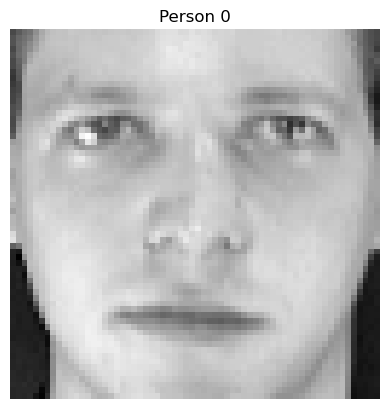

In [40]:
# Selecting an image
plt.imshow(X[0], cmap=plt.cm.gray)
plt.title(f"Person {y[0][0]}")
plt.axis("off")
plt.show()

### Step 4: Training and testing sets

Setup training and testing sets . Use a 50/50 split for each class (5 training images and 5 test images per person). Print the dimension of each of the feature (image) matrices. Because this is a small dataset, we will also use the test set for validation.

In [41]:
# Creating the training and testing sets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.5,
    stratify=y,        # guarantees 5 train + 5 test images per person
    random_state=42
)

print("X_train:", X_train.shape)   # (200, 64, 64)
print("X_test: ", X_test.shape)    # (200, 64, 64)

# Verify the split is exactly 5/5 per person
print(np.bincount(y_train.ravel()))   # should be forty 5s
print(np.bincount(y_test.ravel()))    # should be forty 5s

X_train: (200, 64, 64)
X_test:  (200, 64, 64)
[5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5
 5 5 5]
[5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5
 5 5 5]


### Step 5: Vector conversion

Convert the vector of response variables to a matrix with 40 columns, with indicators for which person it is (one-hot encoded vectors). Print the dimensions of the new response vectors.

In [42]:
# Conversion
y_train_cat = to_categorical(y_train, num_classes=40)
y_test_cat = to_categorical(y_test, num_classes=40)

print("y_train_cat:", y_train_cat.shape)   # (200, 40)
print("y_test_cat: ", y_test_cat.shape)    # (200, 40)

y_train_cat: (200, 40)
y_test_cat:  (200, 40)


### Step 6: Reshape arrays

Reshape the image arrays so that they have 4 dimensions: (number of images, width of image, height of image, number of channels). For example, the array of training images should be (200, 64, 64, 1). Print the dimensions of the new image arrays.

In [43]:
# Reshape
X_train = X_train.reshape(-1, 64, 64, 1)
X_test = X_test.reshape(-1, 64, 64, 1)

print("X_train:", X_train.shape)   # (200, 64, 64, 1)
print("X_test: ", X_test.shape)    # (200, 64, 64, 1)

X_train: (200, 64, 64, 1)
X_test:  (200, 64, 64, 1)


## Part 2: Model 1

### Step 7: Model 1's Architecture

Fit a convolutional neural network using the following architecture, and print the output from training.
*   1 convolutional layer with:
  * 16 filters (neurons)
  * a window size of 3
  * stride size of 1
  * ReLU activation function
  * padding so that the feature is the same size as the original image
*   1 max pooling layer with:
  * window size of 2
  * stride size of 2
  * no padding
*   1 fully connected output layer with:
  * 40 nodes for each face to predict
  * softmax activation function
*   For training, use the Adam optimizer, 20 epochs, a batch size of 10, and the categorical cross entropy loss function.

In [44]:
input_tensor = Input(shape=(64, 64, 1))

# Convolution Neural Network Model
x = Conv2D(16, kernel_size=3, strides=1, activation="relu",
           padding="same", name="conv1")(input_tensor)
x = MaxPooling2D(pool_size=2, strides=2, padding="valid", name="pool1")(x)
x = Flatten()(x)
output_tensor = Dense(40, activation="softmax")(x)

model1 = Model(inputs=input_tensor, outputs=output_tensor)
model1.summary()


E0000 00:00:1792086901.362074    1356 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1792086901.362827    2149 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1792086901.422976    1356 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 64, 64, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 40)             │       655,400 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 655,560 (2.50 MB)

 Trainable params: 655,560 (2.50 MB)

 Non-trainable params: 0 (0.00 B)

In [45]:
# Compiling model1
model1.compile(optimizer="adam",
               loss="categorical_crossentropy",
               metrics=["accuracy"])

history1 = model1.fit(X_train, y_train_cat,
                      epochs=20,
                      batch_size=10,
                      validation_data=(X_test, y_test_cat))

Epoch 1/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.0150 - loss: 4.5272 - val_accuracy: 0.0250 - val_loss: 3.8424
Epoch 2/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.0150 - loss: 3.7736 - val_accuracy: 0.2300 - val_loss: 3.4890
Epoch 3/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.2800 - loss: 3.2925 - val_accuracy: 0.4550 - val_loss: 3.1101
Epoch 4/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7000 - loss: 2.6409 - val_accuracy: 0.6950 - val_loss: 2.5070
Epoch 5/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8400 - loss: 1.7573 - val_accuracy: 0.7450 - val_loss: 1.9382
Epoch 6/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9050 - loss: 1.1322 - val_accuracy: 0.6900 - val_loss: 1.5363
Epoch 7/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9500 - loss: 0.6846 - val_accuracy: 0.8200 - val_loss: 1.2032
Epoch 8/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9950 - loss: 0.4290 - val_accuracy: 0.8500 - v

### Step 8: Model 1's loss and accuracy

Print the loss and accuracy on the test set.

In [46]:
# Loss and Accuracy
loss1, acc1 = model1.evaluate(X_test, y_test_cat, verbose=0)
print(f"Model 1 test loss: {loss1:.4f}")
print(f"Model 1 test accuracy: {acc1:.4f}")

Model 1 test loss: 0.3741
Model 1 test accuracy: 0.9300


### Step 9: Print image

Pick one of the images from the test set, and print the image.

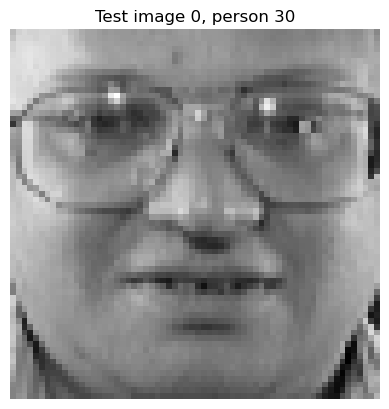

In [47]:
# An image
img_idx = 0
sample = X_test[img_idx]          # shape (64, 64, 1)

plt.imshow(sample.squeeze(), cmap=plt.cm.gray)
plt.title(f"Test image {img_idx}, person {y_test[img_idx][0]}")
plt.axis("off")
plt.show()

### Step 10: Feature maps

For the image you selected in (9), print the images of the feature maps from both the convolutional and pooling layers.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
conv maps: (1, 64, 64, 16)
pool maps: (1, 32, 32, 16)


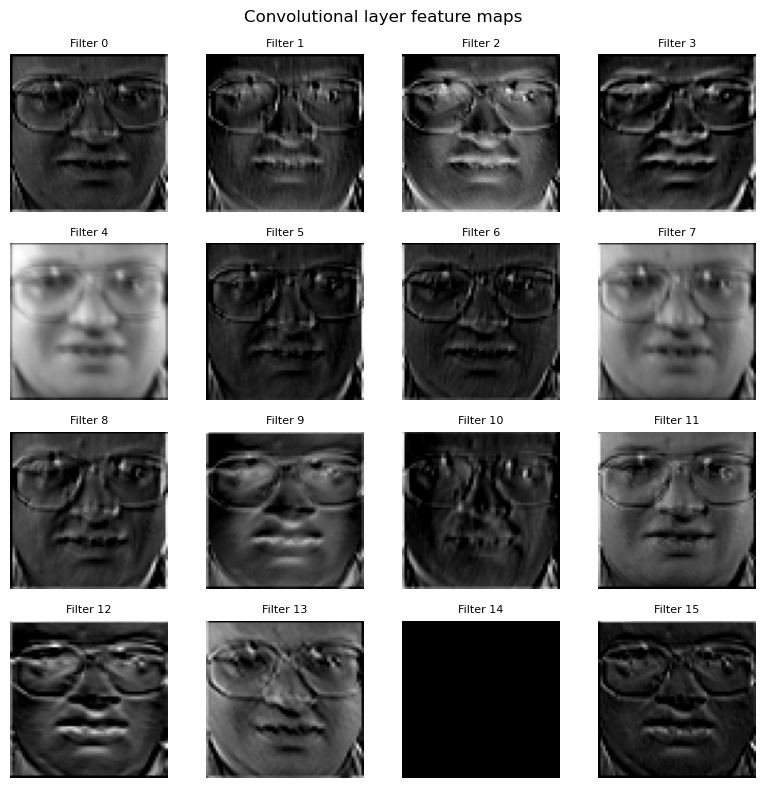

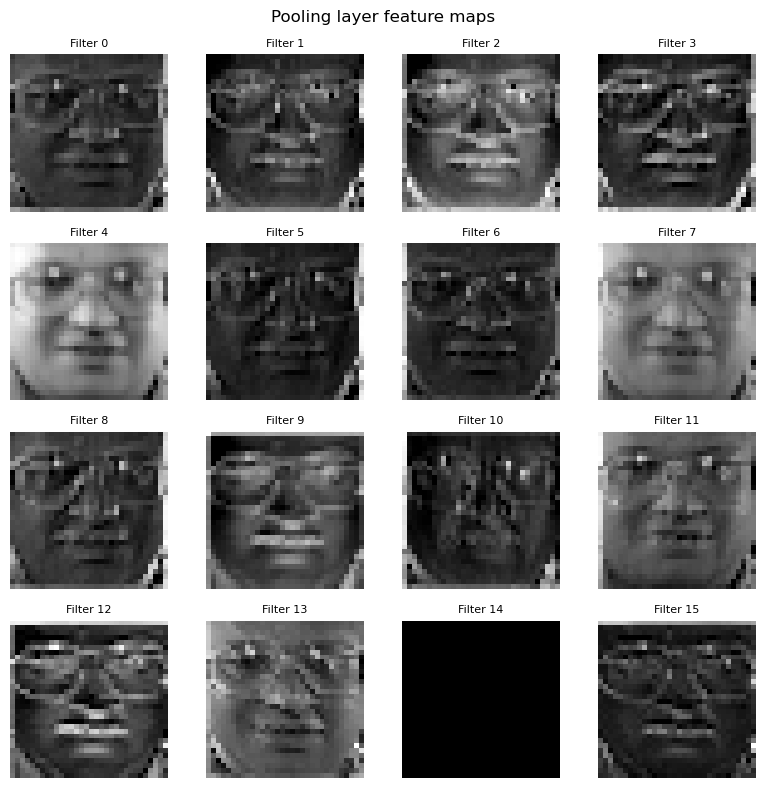

In [48]:
# Feature maps
feature_model = Model(
    inputs=model1.input,
    outputs=[model1.get_layer("conv1").output,
             model1.get_layer("pool1").output]
)

# the model expects a batch, so add a batch dimension: (1, 64, 64, 1)
conv_maps, pool_maps = feature_model.predict(sample[np.newaxis, ...])
print("conv maps:", conv_maps.shape)   # (1, 64, 64, 16)
print("pool maps:", pool_maps.shape)   # (1, 32, 32, 16)

# For loop
for maps, name in [(conv_maps, "Convolutional layer"),
                   (pool_maps, "Pooling layer")]:
    fig, axes = plt.subplots(4, 4, figsize=(8, 8))
    for i, ax in enumerate(axes.flat):
        ax.imshow(maps[0, :, :, i], cmap=plt.cm.gray)
        ax.axis("off")
        ax.set_title(f"Filter {i}", fontsize=8)
    fig.suptitle(f"{name} feature maps")
    plt.tight_layout()
    plt.show()

## Part 3: Model 2




### Step 11: Model 2's Architecture

Fit the model from (7) again, but this time use a window size of 9 for the convolution layer.

In [51]:
# Change model1 so that it has a window size of 9.
input_tensor = Input(shape=(64, 64, 1))

# Convolution Neural Network Model
x = Conv2D(16, kernel_size=9, strides=1, activation="relu",
           padding="same", name="conv1")(input_tensor)
x = MaxPooling2D(pool_size=2, strides=2, padding="valid", name="pool1")(x)
x = Flatten()(x)
output_tensor = Dense(40, activation="softmax")(x)

model2 = Model(inputs=input_tensor, outputs=output_tensor)
model2.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 64, 64, 16)     │         1,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 40)             │       655,400 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 656,712 (2.51 MB)

 Trainable params: 656,712 (2.51 MB)

 Non-trainable params: 0 (0.00 B)

In [52]:
# Compiling model2
model2.compile(optimizer="adam",
               loss="categorical_crossentropy",
               metrics=["accuracy"])

history2 = model2.fit(X_train, y_train_cat,
                      epochs=20,
                      batch_size=10,
                      validation_data=(X_test, y_test_cat))

Epoch 1/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.0100 - loss: 3.7797 - val_accuracy: 0.0450 - val_loss: 3.6876
Epoch 2/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.0400 - loss: 3.6879 - val_accuracy: 0.0250 - val_loss: 3.6831
Epoch 3/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.0700 - loss: 3.6835 - val_accuracy: 0.0950 - val_loss: 3.6772
Epoch 4/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.1050 - loss: 3.6678 - val_accuracy: 0.1600 - val_loss: 3.6408
Epoch 5/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.1500 - loss: 3.6017 - val_accuracy: 0.0900 - val_loss: 3.4932
Epoch 6/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.2150 - loss: 3.4676 - val_accuracy: 0.3350 - val_loss: 3.3672
Epoch 7/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.4350 - loss: 2.9328 - val_accuracy: 0.3350 - val_loss: 2.7070
Epoch 8/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.5700 - loss: 2.0909 - val_accuracy: 0.5450 - v

### Step 12: Model 2's loss and accuracy

Print the loss accuracy on the test set.

In [53]:
# Loss and Accuracy
loss2, acc2 = model2.evaluate(X_test, y_test_cat, verbose=0)
print(f"Model 2 test loss: {loss2:.4f}")
print(f"Model 2 test accuracy: {acc2:.4f}")

Model 2 test loss: 0.3365
Model 2 test accuracy: 0.9200


### Step 13: Feature Maps

Print the feature maps for the model in for the same image you used in (9) and (10).

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
conv maps: (1, 64, 64, 16)
pool maps: (1, 32, 32, 16)


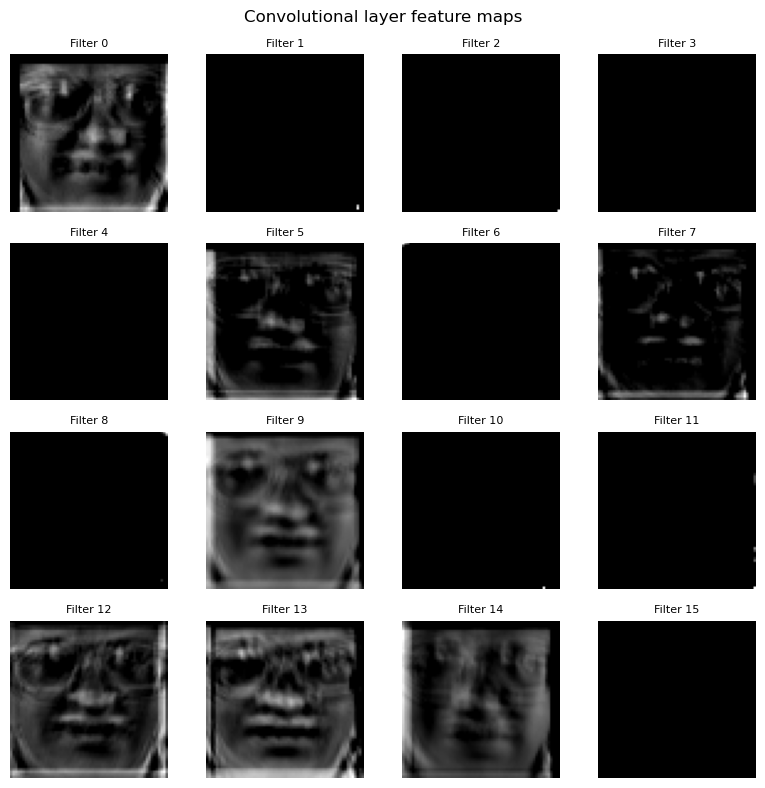

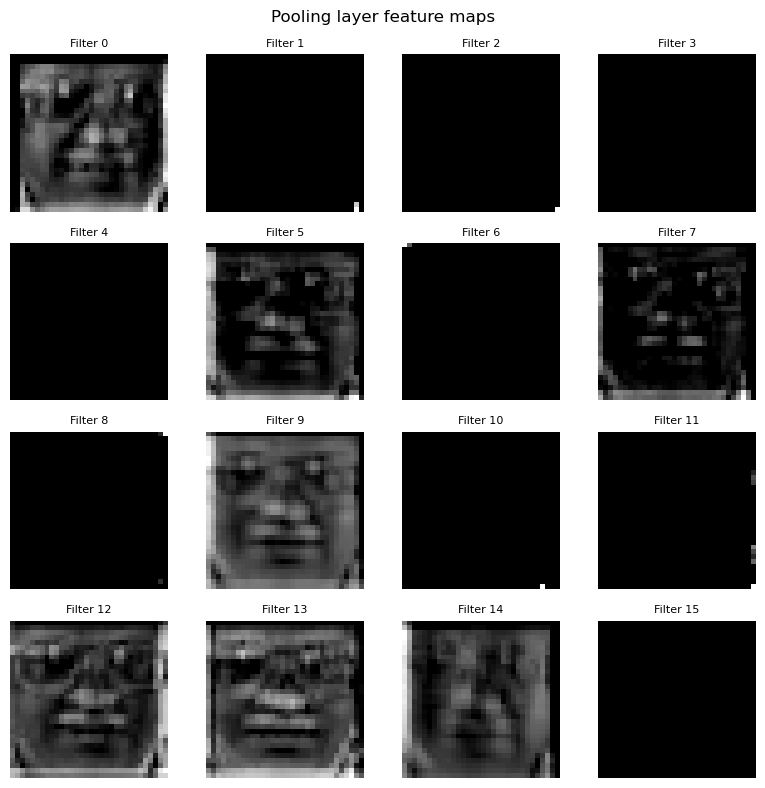

In [54]:
# Feature maps
feature_model = Model(
    inputs=model2.input,
    outputs=[model2.get_layer("conv1").output,
             model2.get_layer("pool1").output]
)

# the model expects a batch, so add a batch dimension: (1, 64, 64, 1)
conv_maps, pool_maps = feature_model.predict(sample[np.newaxis, ...])
print("conv maps:", conv_maps.shape)   # (1, 64, 64, 16)
print("pool maps:", pool_maps.shape)   # (1, 32, 32, 16)

# For loop
for maps, name in [(conv_maps, "Convolutional layer"),
                   (pool_maps, "Pooling layer")]:
    fig, axes = plt.subplots(4, 4, figsize=(8, 8))
    for i, ax in enumerate(axes.flat):
        ax.imshow(maps[0, :, :, i], cmap=plt.cm.gray)
        ax.axis("off")
        ax.set_title(f"Filter {i}", fontsize=8)
    fig.suptitle(f"{name} feature maps")
    plt.tight_layout()
    plt.show()

## Part IV: Model comparison & model optimization


### Step 14: Model comparison

Comment on the differences in the features maps between this model and the previous one. Which network gave better predictions on the test set?

Model 1’s 3x3 filters produce feature maps that stay close to the original face. Fine details like the glasses frames, nose edges, and lip lines are preserved, and almost all 16 filters are active. Model 2’s 9x9 filters respond to larger structures, so a few maps (filters 9 and 14) look smoother and blurrier. But 9 of the 16 maps are almost entirely black, meaning those filters produced no activation for this image, and the active maps show bright bars along the image edges, likely from zero-padding with the larger window. On the test set, Model 1 scored 0.9300 accuracy (loss 0.3741) and Model 2 scored 0.9200 (loss 0.3365). The 1-point accuracy gap is 2 images out of 200, so I don’t consider either model clearly better.

### Step 15: Model 3- Optimized neural network

Optimize the neural network to improve the accuracy on the test set. You should try to get a better accuracy than both of the previous models.  Consider changing the following, then print the accuracy on the test set:
*   Number of convolutional and pooling layers
*   Number of filters in the convolutional layer
*   Window size
*   Number of fully connected layers and neurons
*   Regularization (L1/L2 penalty, dropout, early stopping)
*   Number of epochs and batch size

Call this model `model3`.

In [ ]:
# Convolution Neural Network Model


In [ ]:
# Compiling model3


### Step 16: Reflection on Model 3

Write a few sentences describing how you optimized the model in this part. What worked well?